# **Linear Regression Model: Box Office Revenue Prediction**
### Ciaran O' Toole - C00297672
##### A portfolio produced as part of the Data Science & Machine Learning 1 Module in SE603, Bachelor of Science (Honours) Software Development at SETU

This notebook marks the first modelling stage of my portfolio, focusing on building, training, and evaluating a baseline **Linear Regression** model using my currated and verified dataset of 902 movies prepared in `Datasetcleansing.ipynb` and stored in `movies.csv`. The objective is to investigate whether a movie's production budget alone can accurately predict its worldwide box office revenue.


### **Step 1 - Load My Cleaned Data & Perform Pearson Correlation Analysis (EDA)**

First, I load the verified dataset `movies.csv` containing the 902 movie records. Here I perform a **Pearson Correlation Analysis** between production **budget** and box office **revenue**, alongside a scatter plot, to verify whether there exists a positive linear relationship ($r > 0$) between the two fields.

In [16]:
import pandas as pand
import numpy as np
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plot
#load my data set
movies = pand.read_csv("movies.csv")
correlation = movies["budget"].corr(movies["revenue"])
print(f"Pearson Correlation Coefficient (r): {correlation:.4f}")

Pearson Correlation Coefficient (r): 0.6537


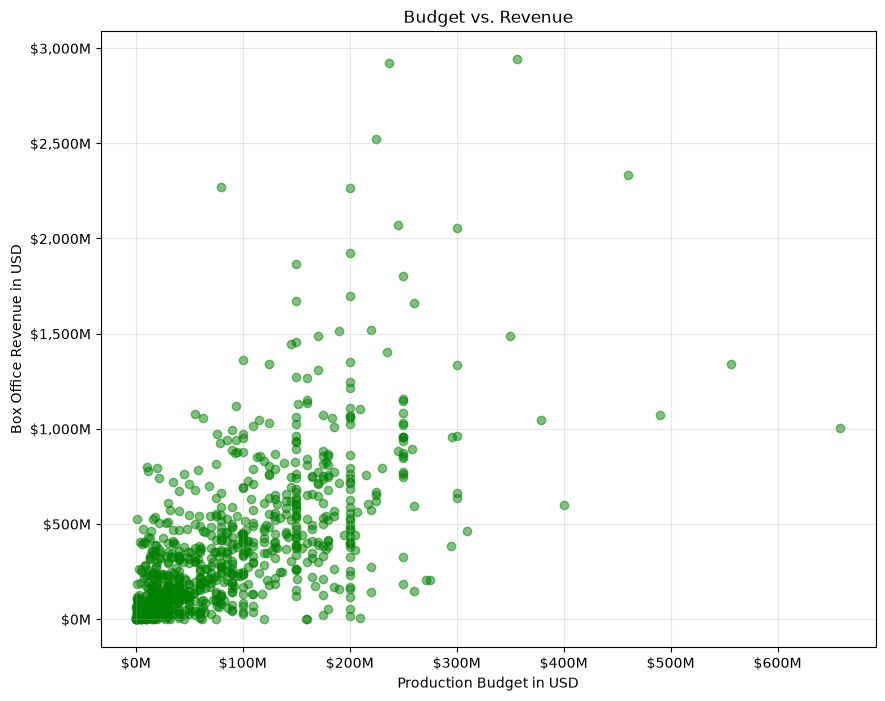

In [ ]:
#displays the x and y nums as Millions rather than just 1 2 3 4 5 etc
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")
plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.5, color="green")

#applies the formatter to the x and y axis
plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)


plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.title("Budget vs. Revenue")
plot.grid(True, alpha=0.3)
plot.show()

Let's add our best fit line on this graph.

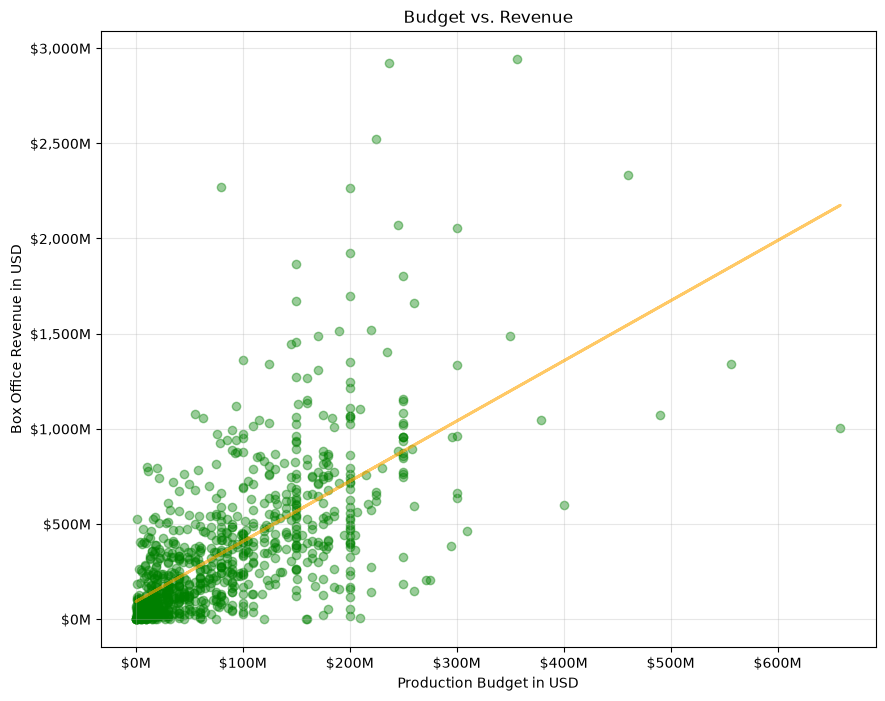

In [45]:
slope, yb = np.polyfit(movies["budget"], movies["revenue"], 1)

plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.4, color="green")
plot.plot(movies["budget"], slope * movies["budget"] + yb, alpha=0.6, color="orange", linewidth=2)

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.title("Budget vs. Revenue")
plot.grid(True, alpha=0.3)
plot.show()

### **Step 2 - Data Preprocessing**

Before training the model, I need to prepare the dataset:

* **Field Selection:** Only **budget** and **revenue** are needed.

* **Train/Test Split:** Split the data into an 80/20 training testing split using `random_state=42` so I know all models are tested on the exact same movies.

* **Z-Score Normalisation:** Scale using standard deviation and training set mean as discussed in the lectures.

In [24]:
from sklearn.model_selection import train_test_split

x = movies[["budget"]]
y = movies["revenue"]
#create the training and test split in an 80/20 ratio
xtrainingset, xtestingset, ytrainingset, ytestingset = train_test_split(x, y, test_size=0.2, random_state=42)

Now that i have divided the movies dataset into its training and testing sets it is time to apply Z-score normalisation using the training set's mean and standard deviation.

In [ ]:
# i use built in functions to get the mean and standard deviation of budget
mean = xtrainingset.mean()
stddev = xtrainingset.std()

xtrainingsetformulated = ((xtrainingset - mean)/stddev)
xtestingsetformulated = ((xtestingset - mean)/stddev)

print(f"training set: {len(xtrainingsetformulated)}")
print(f"testing set: {len(xtestingsetformulated)}")
#print mean and standard deviation to 2 decimal places
print(f"Training Mean Budget: ${mean['budget']:,.2f}")
print(f"Training Standard Deviation: ${stddev['budget']:,.2f}")

training set: 721
testing set: 181
Training Mean Budget: $83,342,429.69
Training Std Dev: $80,553,668.87


### **Step 3 - Model Training**

Now that i have set up my training and testing set and scaled them via Z-Score normalisation, I call sci kits Linear Regression model and fit it on my data.

In [35]:
from sklearn.linear_model import LinearRegression

# set up the model and initialise it so i can train it on my training set
model = LinearRegression()
model.fit(xtrainingsetformulated, ytrainingset)

print(f"Y-Intercept: ${model.intercept_:,.2f}")
print(f"Slope: ${model.coef_[0]:,.2f}")

Y-Intercept: $358,513,481.90
Slope: $258,781,880.06


### **Step 4 - Model Evaluation & Testing**

I evaluate & test the trained model on the 181 unseen test movies **xtestingsetformulated** using three standard regression metrics—**MAE**, **RMSE**, and **$R^2$ Score**—and compare actual vs. predicted revenue for a sample of test movies.

In [44]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# use the trained model to predict revenue for the test set
ypredictions = model.predict(xtestingsetformulated)

# evaluate the accuracy score metrics
rmse = root_mean_squared_error(ytestingset, ypredictions)
r2 = r2_score(ytestingset, ypredictions)
mae = mean_absolute_error(ytestingset, ypredictions)
#output accuracy score metrics
print(f"RMSE: ${rmse:,.2f}")
print(f"MAE: ${mae:,.2f}")
print(f"R2: {r2:.4f}")
print("\n")


#calculate how far off the model is
differences = ytestingset - ypredictions
#make a table and show the predicted vs actual
comparison = pand.DataFrame({
    "Actual Revenue": [f"${m:,.0f}" for m in ytestingset],
    "Predicted Revenue": [f"${m:,.0f}" for m in ypredictions],
    "Difference": [f"${m:,.0f}" for m in differences]
})

print(comparison.head(50))


RMSE: $271,028,017.20
MAE: $187,975,349.03
R2: 0.4484


    Actual Revenue Predicted Revenue     Difference
0   $1,338,073,645    $1,879,514,845  $-541,441,200
1      $72,900,246      $379,901,193  $-307,000,947
2       $3,386,250      $283,524,994  $-280,138,744
3     $499,256,445      $267,462,294   $231,794,151
4      $39,251,917      $283,524,994  $-244,273,077
5      $71,981,823      $103,622,756   $-31,640,933
6     $226,497,209      $395,963,892  $-169,466,683
7     $775,398,007      $126,110,536   $649,287,471
8      $93,722,164      $164,661,015   $-70,938,851
9     $772,775,278      $685,092,489    $87,682,789
10    $397,378,150      $604,778,990  $-207,400,840
11    $153,000,000      $273,887,374  $-120,887,374
12    $566,652,812      $685,092,489  $-118,439,677
13    $475,000,000      $572,653,590   $-97,653,590
14     $33,754,967       $99,693,820   $-65,938,853
15    $340,955,294      $145,385,776   $195,569,518
16    $877,244,782      $395,963,892   $481,280,890
17     $

### **Step 5 - Visualising Test Set Predictions on a Graph**

Now that I have evaluated the accuracy scores, I plot the model's straight prediction line against the actual box office revenues from the testing set to see how well the line fits unseen data.

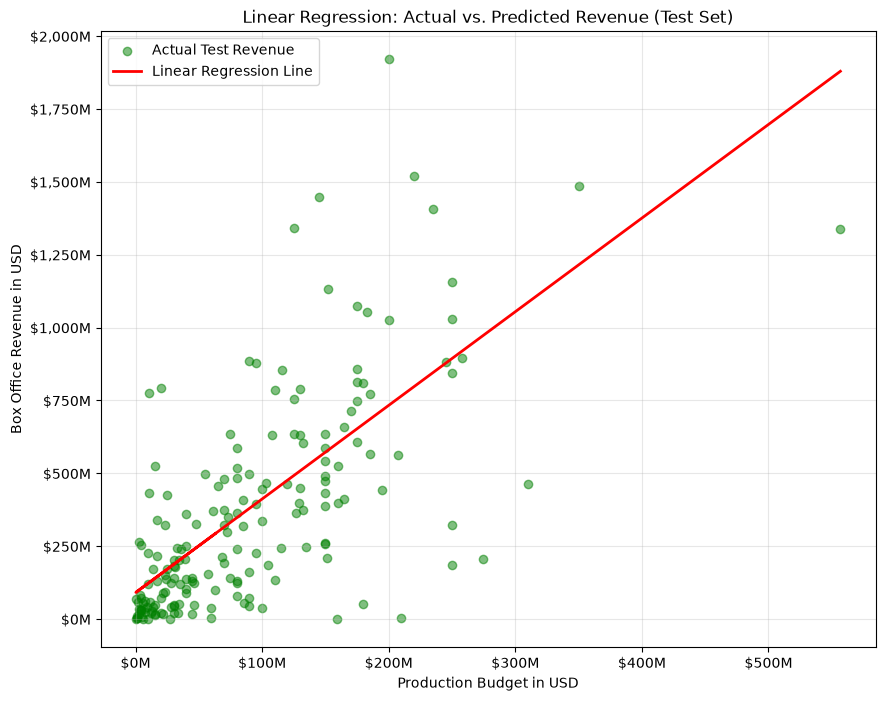

In [46]:
plot.figure(figsize=(10, 8))
plot.scatter(xtestingset["budget"], ytestingset, alpha=0.5, color="green", label="Actual Test Revenue")
plot.plot(xtestingset["budget"], ypredictions, color="red", linewidth=2, label="Linear Regression Line")

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.title("Linear Regression: Actual vs. Predicted Revenue (Test Set)")
plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.legend()
plot.grid(True, alpha=0.3)
plot.show()

### **Step 6 - Export Data for the Website**

Now that I am finished with the procedure on Linear Regression, I need to export this model's outputs to my portfolio website. To do this I need predictions for all 902 movies, then I can gather all the other data like slope, actual revenue, predicted revenue, budget, intercept, mean, R2, MAE, RMSE,etc and save it in a json. This file is so the website's search feature can query results dynamically.

In [47]:
import json
everyprediction = model.predict((movies[["budget"]] - mean) / stddev)

allmovies = []

for i in range(len(movies)):
    iD = movies.iloc[i]
    pred = float(everyprediction[i])
    actual = float(iD["revenue"])
    allmovies.append({
        "title": str(iD["title"]),
        "split": "Testing" if iD.name in xtestingset.index else "Training",
        "budget": round(float(iD["budget"]), 0),
        "actualrevenue": round(actual, 0),
        "predictedrevenue": round(pred, 0),
        "difference": round(actual - pred, 0),
    })

export ={
    "Model":"Linear Regression",
    "Intercept": f"${model.intercept_:,.2f}",
    "Slope": f"${model.coef_[0]:,.2f}",
    "MAE": round(float(mae), 2),
    "RMSE": round(float(rmse), 2),
    "R2": round(float(r2), 4),
    "R2_percentage": round(float(r2) * 100, 1),
    "movies": allmovies
}

with open("linearregression.json", "w") as file:
    json.dump(export, file, indent=4)

### **Conclusion of Linear Regression**

After concluding this Linear Regression Machine Learning segment there is a few things to make note of:

With an $R^2$ Score of 0.4484 on the testing set we can assume to say that production budgets alone can account for roughly 44.84% of box office revenue.

However the straight line base line suggests a good estimate on mid to high budget films, it is quite clear from the MAE ($187,975,349.03) & RMSE ($271,028,017.20) that it struggles with the impact of extreme outliers—underpredicting low-budget breakout hits like **Star Wars** ($11M budget vs. $775.4M revenue) while overpredicting ultra-high-budget films like **Deadpool & Wolverine**.

